# Little Lemon Database

A source-aware MySQL model and Python client for the supplied peer-grade brief. The workbook is retained unchanged. Booking fixtures are separately labeled demonstrations; no unavailable staff, item-price or booking-to-order data is invented.

## 1. Imports and private configuration

All MySQL operations use pooled Connector/Python connections. Credentials are read from a private environment file and are never printed.

In [1]:
from pathlib import Path
from datetime import date, timedelta
from decimal import Decimal
import json, csv, secrets
import mysql.connector
from mysql.connector import Error
from IPython.display import SVG, display
from python.database import ROOT, load_config, create_pool, pooled_cursor, call_procedure
from python.import_workbook import SOURCE_PATH, import_workbook
from python.verify_database import setup_database, verify_database
from python.run_procedures import demonstrate_procedures
from python.tableau_export import export_tableau_data
from scripts.generate_er import compare_schema
print('Connector/Python:',mysql.connector.__version__)
config=load_config()
print('Dedicated database:',config['database'])
pool=create_pool(config)

Connector/Python: 26.10.0
Dedicated database: little_lemon_database
Connecting to MySQL database...
Creating connection pool...
Connection established successfully.
The connection pool is created with a name: little_lemon_database_pool
The pool size is: 2


## 2. Inspect the actual source workbook

The single Orders worksheet has 21 columns and 21,000 rows. Repeated source Order IDs differ in monetary and postal values, so they are preserved. Database Orders.OrderID uses the unique source Row Number; SourceOrderID retains the repeated identifier.

In [2]:
profile=json.loads((ROOT/'data/workbook_profile.json').read_text())
print('Source workbook SHA256:',profile['sha256'])
print('Sheets:',profile['sheet_names'])
print('Rows:',profile['record_count'])
print('Distinct source order IDs:',profile['distinct_source_order_ids'])
for column in profile['columns']:
    print(column['source_name'],column['xlsx_cell_types'],'missing:',column['missing_values'])

Source workbook SHA256: 2bd49d02905992f28762442ad8eb439c648a6ab66d055f9cdb31b79cab438cfb
Sheets: ['Orders']
Rows: 21000
Distinct source order IDs: 1000
Row Number {'n': 21000} missing: 0
Order ID {'s': 21000} missing: 0
Order Date {'n': 21000} missing: 0
Delivery Date {'n': 21000} missing: 0
Customer ID {'s': 21000} missing: 0
Customer Name {'s': 21000} missing: 0
City {'s': 21000} missing: 0
Country {'s': 21000} missing: 0
Postal Code {'s': 8648, 'n': 12352} missing: 0
Country Code {'s': 21000} missing: 0
 Cost {'n': 21000} missing: 0
Sales {'n': 21000} missing: 0
Quantity {'n': 21000} missing: 0
Discount {'n': 21000} missing: 0
Delivery Cost {'n': 21000} missing: 0
Course Name {'s': 21000} missing: 0
Cuisine Name {'s': 21000} missing: 0
Starter Name {'s': 21000} missing: 0
Desert Name {'s': 21000} missing: 0
Drink {'s': 21000} missing: 0
Sides {'s': 21000} missing: 0


## 3. Deploy and import without overwriting

Create only little_lemon_database. Tables and routines use IF NOT EXISTS. Importing compares existing identities and refuses conflicts rather than overwriting them. MySQL DDL has implicit commits; the workbook import is a separate transaction. Existing rows are expected on a rerun.

In [3]:
import_result=setup_database(pool)
print('Source import:',import_result)
verification=verify_database(pool)

Connection acquired from pool.
Closing cursor...
Returning connection to pool...
SQL script committed: create_database.sql
Connection acquired from pool.
Closing cursor...
Returning connection to pool...
SQL script committed: schema.sql
Dedicated database and tables are available: little_lemon_database


Importing actual workbook records into little_lemon_database...
Connection acquired from pool.


Workbook records committed successfully.
Closing cursor...
Returning connection to pool...
Imported source rows: 21000
New records inserted: {'Customers': 0, 'MenuItems': 0, 'Menus': 0, 'MenuComponents': 0, 'Orders': 0, 'OrderDeliveryStatus': 0}
Connection acquired from pool.
Closing cursor...
Returning connection to pool...
SQL script committed: seed_data.sql
Supplemental booking fixtures available; these are not workbook bookings.
Connection acquired from pool.
Closing cursor...
Returning connection to pool...
SQL script committed: stored_procedures.sql
Five required procedures available; existing definitions preserved.
Source import: {'source_record_count': 21000, 'source_sha256': '2bd49d02905992f28762442ad8eb439c648a6ab66d055f9cdb31b79cab438cfb', 'inserted_counts': {'Customers': 0, 'MenuItems': 0, 'Menus': 0, 'MenuComponents': 0, 'Orders': 0, 'OrderDeliveryStatus': 0}, 'row_counts': {'Customers': 1000, 'MenuItems': 30, 'Menus': 72, 'MenuComponents': 360, 'Orders': 21000, 'OrderDeli

Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
{
  "DatabaseName": "little_lemon_database",
  "ServerVersion": "8.4.13",
  "row_counts": {
    "Customers": 1000,
    "MenuItems": 30,
    "Menus": 72,
    "MenuComponents": 360,
    "Orders": 21000,
    "OrderDeliveryStatus": 21000,
    "Bookings": 4
  },
  "summary": {
    "WorkbookRecords": 21000,
    "DistinctSourceOrderIDs": 1000,
    "MaxQuantity": 3,
    "TotalQuantity": "44625",
    "SalesMeasureTotal": "4631847.0300",
    "CostMeasureTotal": "3087898.0200",
    "DiscountMeasureTotal": "1032361.9800",
    "DeliveryCostMeasureTotal": "1070484.6600"
  },
  "delivery_before_order_count": 9366,
  "procedures": [
    "AddBooking",
    "CancelBooking",
    "GetMaxQuantity",
    "ManageBooking",
    "UpdateBooking"
  ]
}
Actual workbook records, constraints and procedure availability verified.


## 4. Verify the deployed ER model

The supplied PNG and PDF are generated from live information_schema columns, keys and foreign keys. The checked manifest must match this deployment. No .mwb is claimed because MySQL Workbench is unavailable.

Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
ER metadata equals the deployed seven-table schema.


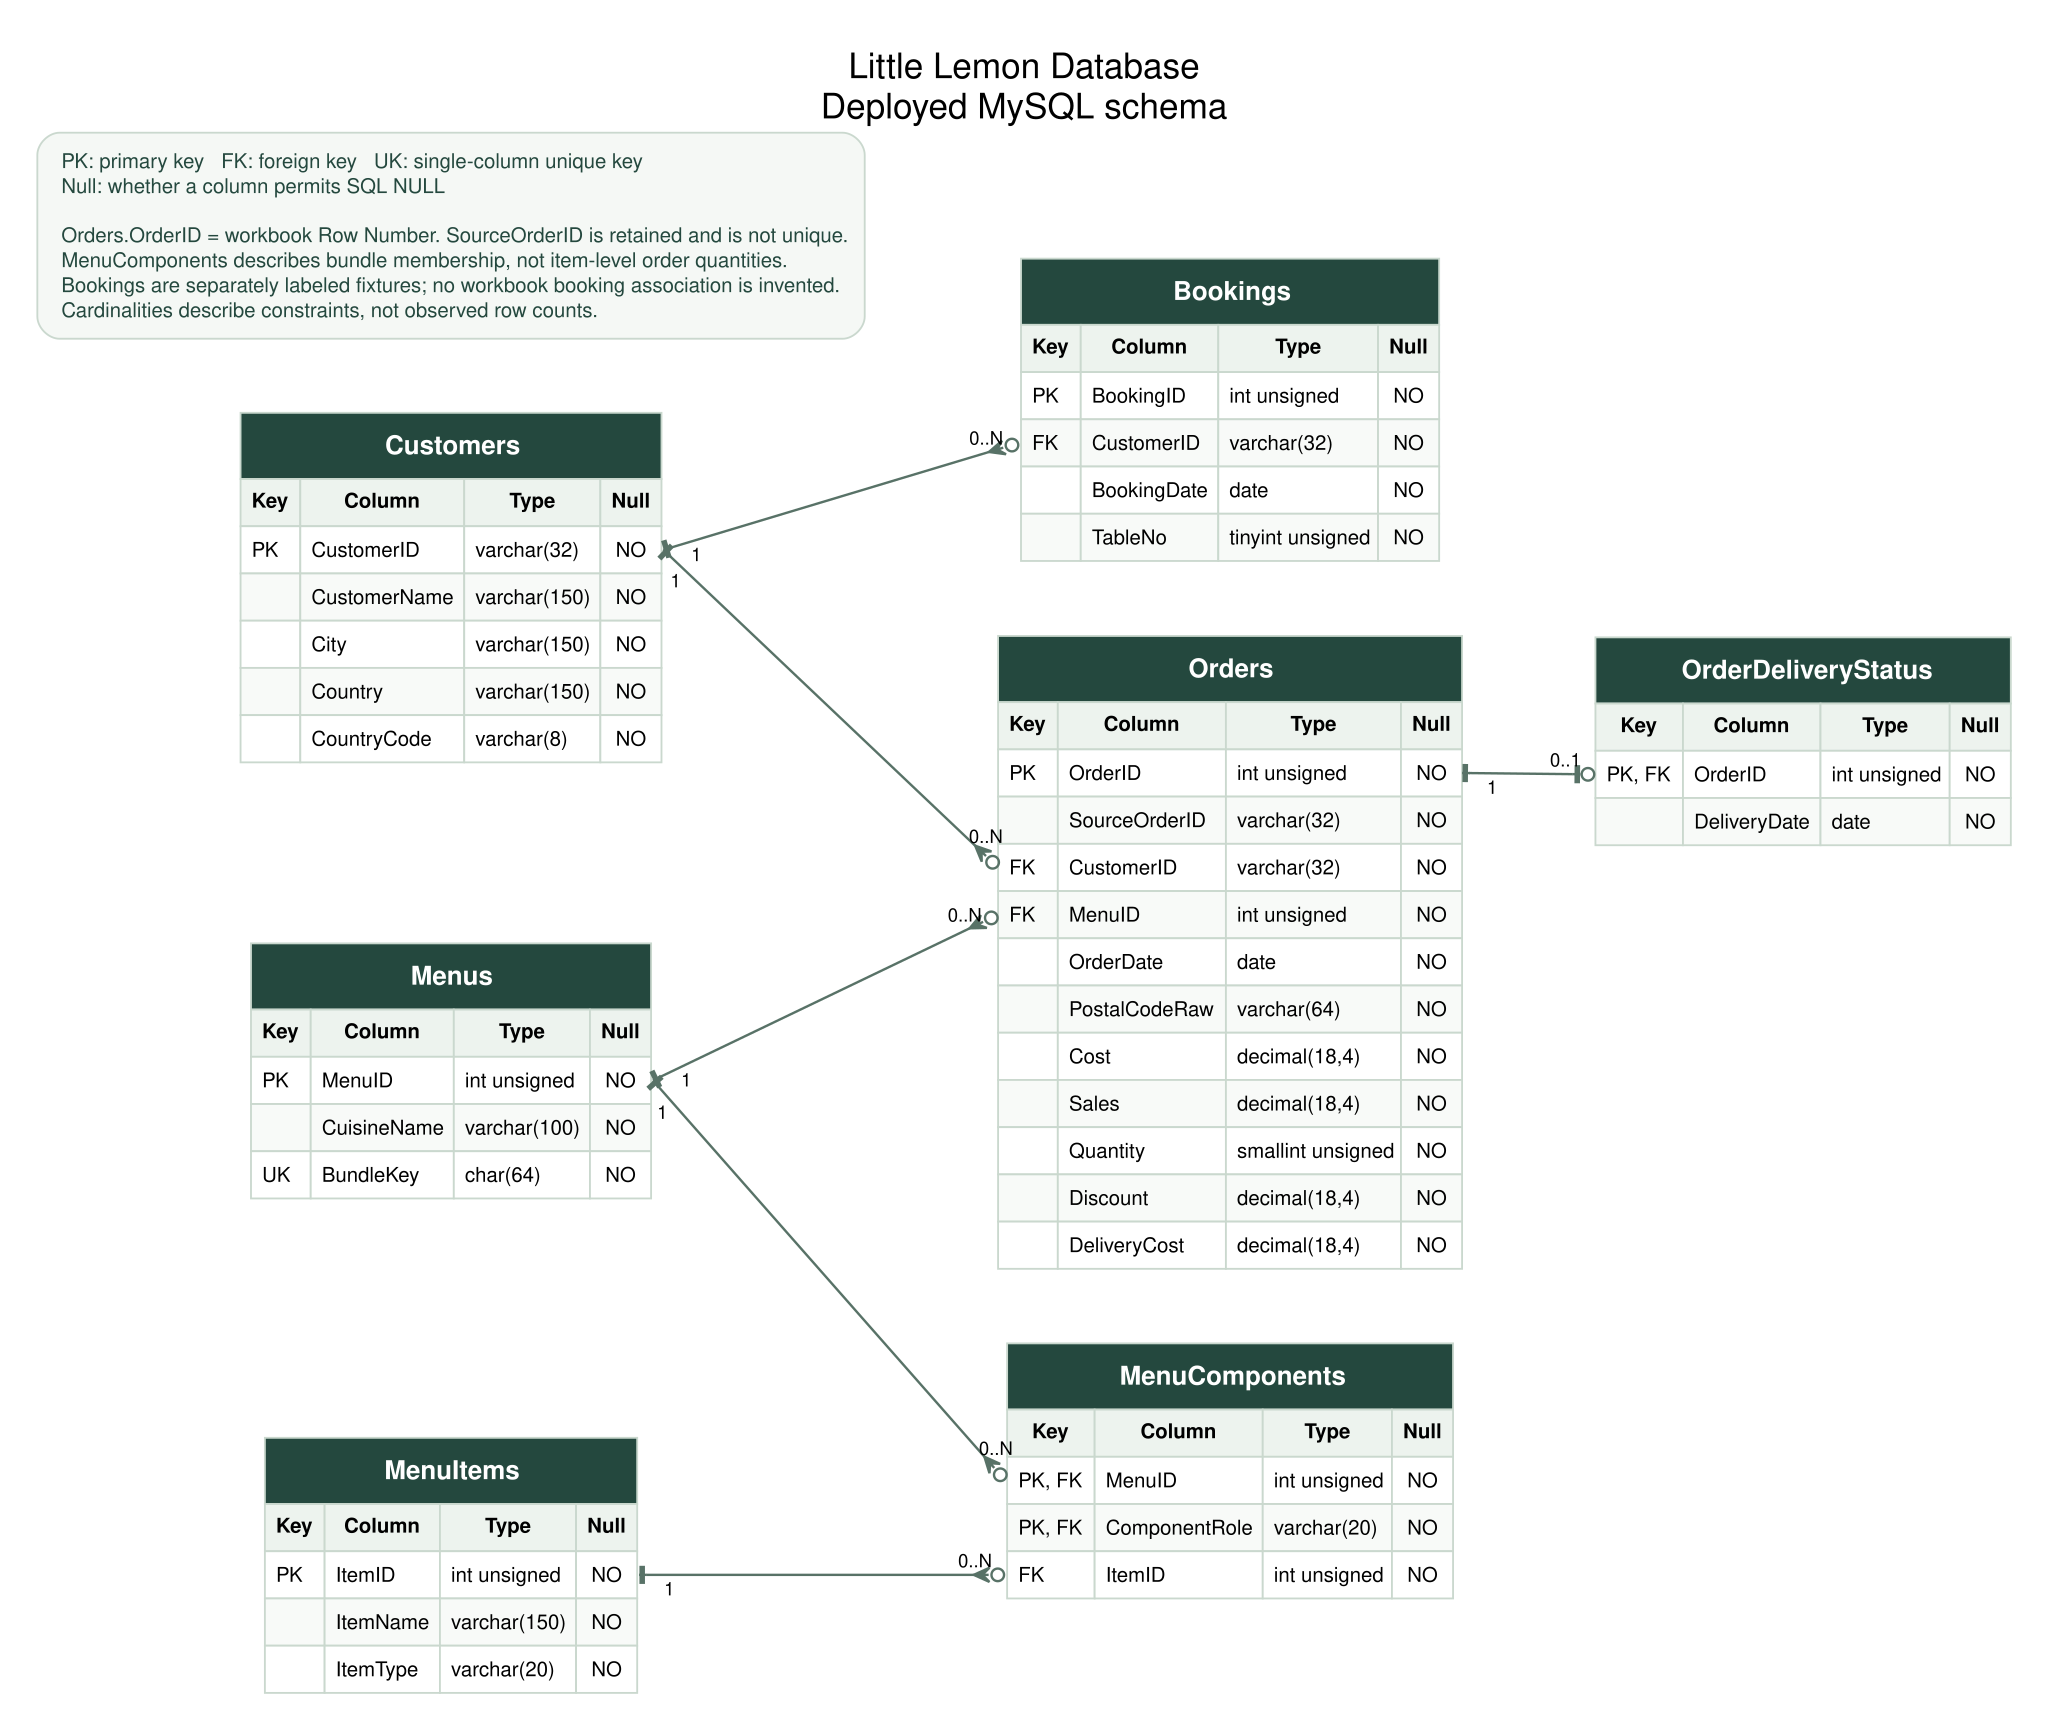

In [4]:
assert compare_schema(pool)
print('ER metadata equals the deployed seven-table schema.')
display(SVG(filename=str(ROOT/'diagrams/little_lemon_er_diagram.svg')))

## 5. Execute all five required procedures

GetMaxQuantity returns MAX(Orders.Quantity). ManageBooking checks a date/table, UpdateBooking changes the date, AddBooking creates a row, and CancelBooking removes it. Historical dates remain valid for course-era examples. The demo changes only its own temporary booking.

In [5]:
procedure_demo=demonstrate_procedures(pool)
print(procedure_demo)

Calling GetMaxQuantity
Connection acquired from pool.
(3,)
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Calling ManageBooking
Connection acquired from pool.
('Table 1 is already booked', 1)
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Calling ManageBooking
Connection acquired from pool.
('Table 48 is available', 0)
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Calling AddBooking
Connection acquired from pool.
(1121023427, 'New booking 1121023427 added; commit required')
Changes committed successfully.
Closing cursor...
Returning connection to pool...
Calling ManageBooking


Connection acquired from pool.
('Table 48 is already booked', 1)
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Calling UpdateBooking
Connection acquired from pool.
(1121023427, 'Booking 1121023427 updated; commit required')


Changes committed successfully.
Closing cursor...
Returning connection to pool...
Connection acquired from pool.
Updated date persisted to a subsequent pooled checkout.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Calling CancelBooking
Connection acquired from pool.
(1121023427, 'Booking 1121023427 cancelled; commit required')
Changes committed successfully.
Closing cursor...
Returning connection to pool...
Calling UpdateBooking
Connection acquired from pool.
Error code: 1644
Error message: Booking does not exist
Closing cursor...
Returning connection to pool...
Expected missing-booking result: 1644 Booking does not exist
Calling CancelBooking
Connection acquired from pool.
Error code: 1644
Error message: Booking does not exist
Closing cursor...
Returning connection to pool...
Expected missing-booking result: 1644 Booking does not exist
All five procedures executed; temporary booking removed.
{'procedures_executed': 5, 'temporary_booking_remove

## 6. Retrieve results and demonstrate commits

The following cell shows callproc, stored_results and commit directly. A second pooled checkout confirms persistence. Finally, it cancels only the newly created record. The connector deprecates stored_results, but the tested pinned version still supports this requested assignment API.

In [6]:
with pooled_cursor(pool) as (connection,cursor):
    cursor.execute('SELECT CustomerID FROM Customers ORDER BY CustomerID LIMIT 1')
    customer_id=cursor.fetchone()[0]
    while True:
        own_id=1_300_000_000+secrets.randbelow(100_000_000)
        own_day=date.today()+timedelta(days=400+secrets.randbelow(500))
        cursor.execute('SELECT COUNT(*) FROM Bookings WHERE BookingID=%s OR (BookingDate=%s AND TableNo=47)',(own_id,own_day))
        if cursor.fetchone()[0]==0:break
created=False
try:
    with pooled_cursor(pool) as (connection,cursor):
        cursor.callproc('AddBooking',(own_id,customer_id,own_day,47))
        for result in cursor.stored_results():
            try:
                for row in result.fetchall():print(row)
            finally:result.close()
        connection.commit()
        created=True
        print('Insert committed.')
    with pooled_cursor(pool) as (connection,cursor):
        cursor.execute('SELECT COUNT(*) FROM Bookings WHERE BookingID=%s',(own_id,))
        assert cursor.fetchone()[0]==1
        print('A subsequent checkout sees the committed booking.')
finally:
    if created:call_procedure(pool,'CancelBooking',(own_id,),commit=True)

Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Connection acquired from pool.
(1385638870, 'New booking 1385638870 added; commit required')
Insert committed.
Closing cursor...
Returning connection to pool...
Connection acquired from pool.
A subsequent checkout sees the committed booking.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Calling CancelBooking
Connection acquired from pool.
(1385638870, 'Booking 1385638870 cancelled; commit required')


Changes committed successfully.
Closing cursor...
Returning connection to pool...


/tmp/ipykernel_314325/1434061355.py:13: DeprecationWarning: Call to deprecated function stored_results. Reason: The property counterpart 'stored_results' will be added in a future release, and this method will be removed.
  for result in cursor.stored_results():


## 7. Preserve and report data-quality findings

No currency is identified. The meaning of Discount is unspecified, so it is not applied as an invented percentage or subtracted again. Four decimal places preserve genuine half-cent Sales values. Delivery chronology and raw postal anomalies remain traceable.

In [7]:
print('Rows with delivery before order:',profile['delivery_before_order_count'])
print('Negative raw postal values:',profile['negative_numeric_postal_codes'])
print('Financial normalization:',json.dumps(profile['financial_fields'],indent=2))
print('Maximum order quantity:',call_procedure(pool,'GetMaxQuantity')[0][0][0])

Rows with delivery before order: 9366
Negative raw postal values: 3701
Financial normalization: {
  "Cost": {
    "minimum": "44.5700",
    "maximum": "320.0000",
    "source_xml_sum": "3087898.01999999999046",
    "normalized_four_decimal_sum": "3087898.0200",
    "sum_if_each_row_rounded_to_cents": "3087898.02",
    "values_with_genuine_fractional_cents": 0
  },
  "Sales": {
    "minimum": "66.8550",
    "maximum": "480.0000",
    "source_xml_sum": "4631847.029999999984750",
    "normalized_four_decimal_sum": "4631847.0300",
    "sum_if_each_row_rounded_to_cents": "4631847.04",
    "values_with_genuine_fractional_cents": 5726
  },
  "Discount": {
    "minimum": "9.1200",
    "maximum": "99.2400",
    "source_xml_sum": "1032361.9799999999980366",
    "normalized_four_decimal_sum": "1032361.9800",
    "sum_if_each_row_rounded_to_cents": "1032361.98",
    "values_with_genuine_fractional_cents": 0
  },
  "DeliveryCost": {
    "minimum": "1.1100",
    "maximum": "99.9100",
    "source_xml

(3,)
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Maximum order quantity: 3


## 8. Export Tableau-ready data without fan-out

The fact export pivots five component roles into columns before joining. It keeps one row per workbook row; joining five components directly and summing Sales would multiply results by five. Tableau Desktop is NOT VERIFIED and no native workbook is fabricated.

In [8]:
exports=export_tableau_data(pool)
print('Export row counts:',{name:info['rows'] for name,info in exports.items() if isinstance(info,dict) and 'rows' in info})
with (ROOT/'tableau/order_facts.csv').open(newline='',encoding='utf-8') as stream:
    facts=list(csv.DictReader(stream))
assert len(facts)==21000
assert sum(Decimal(row['Sales']) for row in facts)==Decimal('4631847.0300')
print('Fact export sales measure total:',sum(Decimal(row['Sales']) for row in facts))

Connection acquired from pool.


Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
Verified Tableau-ready exports: {'order_facts.csv': 21000, 'bookings.csv': 4, 'menu_components.csv': 360, 'sales_by_month.csv': 44, 'sales_by_cuisine.csv': 3}
Export row counts: {'order_facts.csv': 21000, 'bookings.csv': 4, 'menu_components.csv': 360, 'sales_by_month.csv': 44, 'sales_by_cuisine.csv': 3}


Fact export sales measure total: 4631847.0300


## 9. Source-measure analysis preview

This Python chart is a verified preview, not a Tableau screenshot or a real-business revenue claim. It sums all preserved workbook rows, in source units. Use tableau/README.md to build and verify a genuine Tableau workbook elsewhere.

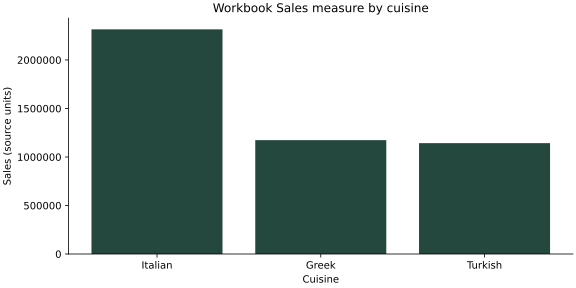

In [9]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
with (ROOT/'tableau/sales_by_cuisine.csv').open(newline='',encoding='utf-8') as stream:
    cuisine=list(csv.DictReader(stream))
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
ax.bar([r['CuisineName'] for r in cuisine],[float(r['SalesMeasureTotal']) for r in cuisine],color='#24483e')
ax.set(title='Workbook Sales measure by cuisine',ylabel='Sales (source units)',xlabel='Cuisine')
ax.spines[['top','right']].set_visible(False)
ax.ticklabel_format(axis='y',style='plain')
path=ROOT/'output/sales_measure_by_cuisine.svg'
path.parent.mkdir(exist_ok=True)
fig.savefig(path,metadata={'Creator':'Abdulrahman M. Yaqyn','Date':None})
plt.close(fig)
display(SVG(filename=str(path)))

## 10. Cleanup and repeatability

A deliberately handled SQL error must not exhaust the pool. All uncommitted writes roll back on cleanup, every cursor closes, and every checkout returns to the pool. Physical pooled sockets are reused until the kernel exits.

In [10]:
from contextlib import ExitStack
try:
    with pooled_cursor(pool) as (connection,cursor):cursor.execute('SELECT DeliberatelyMissingColumn FROM Customers')
except Error as er:
    print('Expected error handled:',er.errno,er.msg)
with ExitStack() as stack:
    for number in range(pool.pool_size):
        connection,cursor=stack.enter_context(pooled_cursor(pool))
        cursor.execute('SELECT 1');assert cursor.fetchone()[0]==1
        print('Reusable pool slot:',number+1)
again=import_workbook(pool)
assert all(n==0 for n in again['inserted_counts'].values())
final=verify_database(pool)
assert final['row_counts']['Bookings']==4
print('All acquired connections returned; workbook rerun inserted zero duplicates.')
print('Notebook completed without unexpected errors.')

Connection acquired from pool.
Error code: 1054
Error message: Unknown column 'DeliberatelyMissingColumn' in 'field list'
Closing cursor...
Returning connection to pool...
Expected error handled: 1054 Unknown column 'DeliberatelyMissingColumn' in 'field list'
Connection acquired from pool.
Reusable pool slot: 1
Connection acquired from pool.
Reusable pool slot: 2
Closing cursor...
Returning connection to pool...
Closing cursor...
Returning connection to pool...


Importing actual workbook records into little_lemon_database...
Connection acquired from pool.


Workbook records committed successfully.
Closing cursor...
Returning connection to pool...
Imported source rows: 21000
New records inserted: {'Customers': 0, 'MenuItems': 0, 'Menus': 0, 'MenuComponents': 0, 'Orders': 0, 'OrderDeliveryStatus': 0}
Connection acquired from pool.
Closing cursor...
Uncommitted transaction rolled back.
Returning connection to pool...
{
  "DatabaseName": "little_lemon_database",
  "ServerVersion": "8.4.13",
  "row_counts": {
    "Customers": 1000,
    "MenuItems": 30,
    "Menus": 72,
    "MenuComponents": 360,
    "Orders": 21000,
    "OrderDeliveryStatus": 21000,
    "Bookings": 4
  },
  "summary": {
    "WorkbookRecords": 21000,
    "DistinctSourceOrderIDs": 1000,
    "MaxQuantity": 3,
    "TotalQuantity": "44625",
    "SalesMeasureTotal": "4631847.0300",
    "CostMeasureTotal": "3087898.0200",
    "DiscountMeasureTotal": "1032361.9800",
    "DeliveryCostMeasureTotal": "1070484.6600"
  },
  "delivery_before_order_count": 9366,
  "procedures": [
    "AddBoo

## 11. Conclusion

The actual workbook supports the customer/menu/order/delivery model; supplemental fixtures support the booking routines. Source quality issues, repeated IDs and unknown units remain explicit. The ER diagram and MySQL model agree. Native Workbench and Tableau execution remain NOT VERIFIED. Both existing projects are separate and preserved. See the rubric checklist and evidence files for executed results and limitations.